# Phase 1 — First look at TCGA-BRCA

**Author:** Setayesh Hoseini
**Course:** Statistics — Fall 1405
**Date:** 1405-08-12
**Path:** ب (TCGA-BRCA multi-omic)

## Goal of this notebook
1. Audit the raw structure of the TCGA-BRCA clinical table.
2. Diagnose and document its row duplication.
3. Collapse it to a clean **one-row-per-patient** table.
4. Map RNA-seq files to patients, merge, and produce
   first descriptive plots.

## Data
- Clinical: `data/raw/clinical/clinical.tsv` (GDC export, 2026-10-31)
- RNA-seq : `data/raw/rnaseq/<file_id>/<file_id>.rna_seq...tsv` (1,231 files)

## 1. Setup and raw load

In [1]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

CLINICAL_PATH = "../data/raw/clinical/clinical.tsv"
RNASEQ_DIR    = "../data/raw/rnaseq"

assert os.path.exists(CLINICAL_PATH), f"File not found: {os.path.abspath(CLINICAL_PATH)}"
assert os.path.isdir(RNASEQ_DIR),     f"Dir not found:  {os.path.abspath(RNASEQ_DIR)}"

# RNA-seq files (verified earlier: 1,231)
rnaseq_files = glob.glob(os.path.join(RNASEQ_DIR, "*", "*.tsv"))
print("RNA-seq .tsv files found:", len(rnaseq_files))

# Raw clinical table
df = pd.read_csv(CLINICAL_PATH, sep="\t", low_memory=False)
print("Raw clinical shape:", df.shape)

RNA-seq .tsv files found: 1231
Raw clinical shape: (5546, 202)


### Column audit
The clinical table is node-prefixed: `cases.*`, `demographic.*`,
`diagnoses.*`, `treatments.*`. The patient key is `cases.case_id`.
GDC stores missing values as the literal string `"'--"` (not `NaN`).
Boolean flags are lowercase strings (`"true"` / `"false"`).

In [2]:
print("All columns (%d):" % df.shape[1])
for c in df.columns:
    print(" ", c)

All columns (202):
  project.project_id
  cases.case_id
  cases.consent_type
  cases.days_to_consent
  cases.days_to_lost_to_followup
  cases.disease_type
  cases.index_date
  cases.lost_to_followup
  cases.primary_site
  cases.submitter_id
  demographic.age_at_index
  demographic.age_is_obfuscated
  demographic.cause_of_death
  demographic.cause_of_death_source
  demographic.country_of_birth
  demographic.country_of_residence_at_enrollment
  demographic.days_to_birth
  demographic.days_to_death
  demographic.demographic_id
  demographic.education_level
  demographic.ethnicity
  demographic.marital_status
  demographic.occupation_duration_years
  demographic.population_group
  demographic.race
  demographic.sex_at_birth
  demographic.submitter_id
  demographic.vital_status
  demographic.year_of_birth
  demographic.year_of_birth_range
  demographic.year_of_death
  diagnoses.adrenal_hormone
  diagnoses.age_at_diagnosis
  diagnoses.ajcc_clinical_m
  diagnoses.ajcc_clinical_n
  diagnoses.a

## 2. Diagnose the row duplication

The raw table has **5,546 rows** but only **1,098 unique patients**.
The goal of this section is to prove that the duplication is
**structural** (patient × diagnosis × treatment), not a data error.

In [3]:
print("Total rows:              ", len(df))
print("Unique case_id:          ", df["cases.case_id"].nunique())
print("Unique submitter_id:     ", df["cases.submitter_id"].nunique())

print("\nDistribution of rows per case:")
print(df.groupby("cases.case_id").size().value_counts().sort_index())

print("\nUnique (case, diagnosis) pairs:",
      df.groupby(["cases.case_id", "diagnoses.diagnosis_id"]).ngroups)
print("Unique (case, treatment) pairs:",
      df.groupby(["cases.case_id", "treatments.treatment_id"]).ngroups)

Total rows:               5546
Unique case_id:           1098
Unique submitter_id:      1098

Distribution of rows per case:
1      68
2       5
3     326
4     131
5     165
6     177
7      90
8      50
9      26
10     14
11     13
12     10
13      2
14      6
15      3
16      2
17      3
19      2
20      1
21      1
22      1
33      1
40      1
Name: count, dtype: int64

Unique (case, diagnosis) pairs: 1343
Unique (case, treatment) pairs: 5537


**Interpretation.** Rows ≈ (case × treatment) pairs
(5,546 vs 5,537), so the row explosion is driven by treatments,
not by diagnoses. Diagnosis contributes ~245 extra rows
(1,343 pairs vs 1,098 patients).

## 3. Collapse to one row per patient

**Rule (documented in `data/README.md`):**
1. Keep `diagnoses.diagnosis_is_primary_disease == "true"` (case-insensitive).
2. Drop all `treatments.*` columns (row-explosion driver).
3. Sort by `diagnoses.days_to_diagnosis`, then `drop_duplicates(cases.case_id)`.
4. Rows with `'--` in the primary-disease flag are excluded (2 patients).

In [4]:
print("Raw values of primary-disease flag:")
print(df["diagnoses.diagnosis_is_primary_disease"].value_counts(dropna=False))

is_primary = (
    df["diagnoses.diagnosis_is_primary_disease"]
      .astype(str).str.lower() == "true"
)
prim = df[is_primary].copy()

print("\nAfter primary filter:")
print("  rows:", len(prim), "| unique cases:", prim["cases.case_id"].nunique())

invalid = df[df["diagnoses.diagnosis_is_primary_disease"] == "'--"]
print("\nRows with missing flag ('--):", len(invalid),
      "| unique cases:", invalid["cases.case_id"].nunique())

Raw values of primary-disease flag:
diagnoses.diagnosis_is_primary_disease
true     4946
false     597
'--         3
Name: count, dtype: int64

After primary filter:
  rows: 4946 | unique cases: 1096

Rows with missing flag ('--): 3 | unique cases: 2


In [5]:
tx_cols     = [c for c in prim.columns if c.startswith("treatments.")]
prim_no_tx  = prim.drop(columns=tx_cols).copy()
print("After dropping treatment columns:", prim_no_tx.shape)

prim_no_tx["diagnoses.days_to_diagnosis"] = pd.to_numeric(
    prim_no_tx["diagnoses.days_to_diagnosis"], errors="coerce"
)
prim_no_tx = prim_no_tx.sort_values(
    ["cases.case_id", "diagnoses.days_to_diagnosis"]
)
patient = prim_no_tx.drop_duplicates(subset="cases.case_id", keep="first").copy()

print("\nFinal patient-level table:")
print("  shape:", patient.shape)
print("  unique cases:", patient["cases.case_id"].nunique())
print("  is_unique per case:", patient["cases.case_id"].is_unique)

os.makedirs("../data/processed", exist_ok=True)
patient.to_csv("../data/processed/clinical_patient_level.csv", index=False)
print("Saved → data/processed/clinical_patient_level.csv")

After dropping treatment columns: (4946, 158)

Final patient-level table:
  shape: (1096, 158)
  unique cases: 1096
  is_unique per case: True
Saved → data/processed/clinical_patient_level.csv


**Result.** One row per patient, `cases.case_id` unique.
Saved for all downstream phases as
`data/processed/clinical_patient_level.csv`.

Next section: mapping RNA-seq sample barcodes → patients and
selecting one sample per patient for the merged analysis table.

In [6]:
# ============================================================
# BLOCK 2 — Sample sheet: map 1,231 RNA-seq files to patients
# ============================================================

import requests
import json
import pandas as pd
import os

GDC_FILES_ENDPOINT = "https://api.gdc.cancer.gov/files"

# Re-use the exact filters that produced the 1,231 files
filters = {
    "op": "and",
    "content": [
        {"op": "in", "content": {"field": "cases.project.project_id", "value": ["TCGA-BRCA"]}},
        {"op": "in", "content": {"field": "data_category", "value": ["Transcriptome Profiling"]}},
        {"op": "in", "content": {"field": "data_type", "value": ["Gene Expression Quantification"]}},
        {"op": "in", "content": {"field": "experimental_strategy", "value": ["RNA-Seq"]}},
        {"op": "in", "content": {"field": "analysis.workflow_type", "value": ["STAR - Counts"]}}
    ]
}

# Request exactly the fields we need for the sample sheet
fields = ",".join([
    "file_id",
    "file_name",
    "cases.case_id",
    "cases.submitter_id",                      # patient barcode (TCGA-XX-XXXX)
    "cases.samples.sample_id",
    "cases.samples.submitter_id",              # sample barcode (TCGA-XX-XXXX-01A)
    "cases.samples.sample_type",               # 'Primary Tumor', 'Solid Tissue Normal', etc.
    "cases.samples.tissue_type",
])

params = {
    "filters": json.dumps(filters),
    "format": "JSON",
    "size": "2000",                             # > 1231, so we get all in one page
    "fields": fields,
}

resp = requests.get(GDC_FILES_ENDPOINT, params=params)
resp.raise_for_status()
hits = resp.json()["data"]["hits"]
print(f"API returned {len(hits)} file records")

# Flatten the nested JSON into a flat table
rows = []
for h in hits:
    case  = h.get("cases", [{}])[0]
    samp  = case.get("samples", [{}])[0]
    rows.append({
        "file_id":              h["file_id"],
        "file_name":            h["file_name"],
        "case_id":              case.get("case_id"),
        "patient_barcode":      case.get("submitter_id"),          # TCGA-XX-XXXX
        "sample_id":            samp.get("sample_id"),
        "sample_barcode":       samp.get("submitter_id"),          # TCGA-XX-XXXX-01A
        "sample_type":          samp.get("sample_type"),           # 'Primary Tumor' etc.
        "tissue_type":          samp.get("tissue_type"),
    })

sample_sheet = pd.DataFrame(rows)

# Derive the 2-digit sample type code from the barcode (4th segment)
# e.g. TCGA-XX-XXXX-01A -> '01'
sample_sheet["sample_type_code"] = (
    sample_sheet["sample_barcode"]
      .str.split("-").str[3]
      .str[:2]
)

print("\nSample sheet shape:", sample_sheet.shape)
print("\nSample type breakdown:")
print(sample_sheet["sample_type"].value_counts(dropna=False))
print("\nSample type code breakdown:")
print(sample_sheet["sample_type_code"].value_counts(dropna=False))

# Save
os.makedirs("../data/processed", exist_ok=True)
sample_sheet.to_csv("../data/processed/sample_sheet.csv", index=False)
print("\nSaved → data/processed/sample_sheet.csv")

API returned 1231 file records

Sample sheet shape: (1231, 9)

Sample type breakdown:
sample_type
Primary Tumor          1111
Solid Tissue Normal     113
Metastatic                7
Name: count, dtype: int64

Sample type code breakdown:
sample_type_code
01    1111
11     113
06       7
Name: count, dtype: int64

Saved → data/processed/sample_sheet.csv


In [7]:
# ============================================================
# BLOCK 2 — Data-flow table (Path B requirement ب۲)
# ============================================================

# Clinical side
clinical_patients = set(patient["cases.case_id"].unique())  # 1,096

# Molecular side
molecular_patients = set(sample_sheet["case_id"].unique())
molecular_samples  = sample_sheet["sample_id"].nunique()

# Intersection
shared_patients = clinical_patients & molecular_patients

# Primary-tumor-only subset (the analytic choice)
primary = sample_sheet[sample_sheet["sample_type"] == "Primary Tumor"]
primary_patients = set(primary["case_id"].unique())

# Patients with exactly one primary tumor (ideal for 1-row-per-patient merge)
counts = primary.groupby("case_id").size()
one_primary = set(counts[counts == 1].index)

flow = pd.DataFrame([
    ["Clinical table (processed)",        len(clinical_patients),  "1 row per patient"],
    ["RNA-seq files (raw)",                len(sample_sheet),      "1 file per sample"],
    ["RNA-seq unique samples",             molecular_samples,      "unique sample_id"],
    ["RNA-seq unique patients",            len(molecular_patients), "unique case_id"],
    ["Patients in BOTH clinical & RNA-seq",len(shared_patients),   "intersection"],
    ["Patients with ≥1 primary tumor",     len(primary_patients),  "sample_type == Primary Tumor"],
    ["Patients with exactly 1 primary tumor", len(one_primary),    "ideal for merge"],
    ["Final analytic sample size",         len(one_primary),       "clinical ∩ 1 primary tumor"],
], columns=["Step", "Count", "Definition"])

print("\n=== DATA-FLOW TABLE (Path B, ب۲) ===\n")
print(flow.to_string(index=False))

flow.to_csv("../data/processed/data_flow_table.csv", index=False)
print("\nSaved → data/processed/data_flow_table.csv")


=== DATA-FLOW TABLE (Path B, ب۲) ===

                                 Step  Count                   Definition
           Clinical table (processed)   1096            1 row per patient
                  RNA-seq files (raw)   1231            1 file per sample
               RNA-seq unique samples   1226             unique sample_id
              RNA-seq unique patients   1095               unique case_id
  Patients in BOTH clinical & RNA-seq   1093                 intersection
       Patients with ≥1 primary tumor   1095 sample_type == Primary Tumor
Patients with exactly 1 primary tumor   1084              ideal for merge
           Final analytic sample size   1084   clinical ∩ 1 primary tumor

Saved → data/processed/data_flow_table.csv


In [8]:
# ============================================================
# BLOCK 2 — Inspect multi-sample patients (document the exclusion)
# ============================================================

multi = counts[counts > 1].sort_values(ascending=False)
print(f"Patients with >1 Primary Tumor sample: {len(multi)}")
print("\nDistribution of primary-tumor counts per patient:")
print(counts.value_counts().sort_index())

if len(multi) > 0:
    print("\nExamples of multi-sample patients:")
    print(multi.head(10))

Patients with >1 Primary Tumor sample: 11

Distribution of primary-tumor counts per patient:
1    1084
2       6
3       5
Name: count, dtype: int64

Examples of multi-sample patients:
case_id
011b9b2d-ebe5-42bf-9662-d922faccc7a1    3
8785012f-f73e-4d68-87cf-1d804af32782    3
6cb6f179-defd-4661-af0a-c353b74c0c49    3
8c7e74e0-71ef-49b8-9217-94b8ef740ef9    3
f130f376-5801-40f9-975d-a7e2f7b5670d    3
67c5f371-3fa9-47c5-8b15-c2dd9acc8519    2
3b7b9c1e-a84c-47ed-983c-9e4b00cbf01a    2
6cd9baf5-bbe0-4c1e-a87f-c53b3af22890    2
b2ecbc0f-2c30-4200-8d5e-7b95424bcadb    2
cb9f5e50-f49d-4899-8895-9367afcc1015    2
dtype: int64


### Block 2 — Correction and finalization

**Correction to the data-flow table above:** the row
`Final analytic sample size = 1084` counted patients with exactly one
primary tumor, but did **not** intersect with the clinical patient set.
The corrected value is computed below.

**Duplicate sample_ids:** 5 sample_ids have multiple quantification files
(aliquots). Since the analytic unit is the **patient**, this does not affect
the final sample. One file per patient is retained; the rest are documented.

In [9]:
# ============================================================
# FIX 1 — Correct the final analytic sample size
# ============================================================
# Correct definition:
#   final = (patients with exactly 1 primary tumor) ∩ (clinical patients)

single_primary_ids  = set(counts[counts == 1].index)       # from earlier cell
clinical_ids        = set(patient["cases.case_id"].unique())

final_ids = single_primary_ids & clinical_ids
print(f"Final analytic sample = clinical ∩ exactly-1-primary-tumor: {len(final_ids)}")

# Break down the 11 multi-primary-tumor patients
multi_ids = set(counts[counts > 1].index)
print(f"  Multi-primary-tumor patients: {len(multi_ids)} "
      f"(of which {len(multi_ids & clinical_ids)} are in clinical)")
print(f"  Dropped from clinical (no RNA-seq): "
      f"{len(clinical_ids - single_primary_ids - multi_ids)}")

# Rebuild the corrected data-flow table
flow_corrected = pd.DataFrame([
    ["Clinical table (processed)",            len(clinical_ids),          "1 row per patient"],
    ["RNA-seq files (raw)",                   len(sample_sheet),          "1 file per sample"],
    ["RNA-seq unique samples",                sample_sheet["sample_id"].nunique(), "unique sample_id"],
    ["RNA-seq unique patients",               len(molecular_patients),    "unique case_id"],
    ["Patients in BOTH clinical & RNA-seq",   len(clinical_ids & molecular_patients), "intersection"],
    ["Patients with exactly 1 primary tumor", len(single_primary_ids),    "the analytic candidate pool"],
    ["Final analytic sample",                 len(final_ids),             "clinical ∩ exactly-1-primary-tumor"],
], columns=["Step", "Count", "Definition"])

print("\n=== CORRECTED DATA-FLOW TABLE (Path B, ب۲) ===\n")
print(flow_corrected.to_string(index=False))

flow_corrected.to_csv("../data/processed/data_flow_table.csv", index=False)
print("\nSaved (overwritten) → data/processed/data_flow_table.csv")

Final analytic sample = clinical ∩ exactly-1-primary-tumor: 1083
  Multi-primary-tumor patients: 11 (of which 10 are in clinical)
  Dropped from clinical (no RNA-seq): 3

=== CORRECTED DATA-FLOW TABLE (Path B, ب۲) ===

                                 Step  Count                         Definition
           Clinical table (processed)   1096                  1 row per patient
                  RNA-seq files (raw)   1231                  1 file per sample
               RNA-seq unique samples   1226                   unique sample_id
              RNA-seq unique patients   1095                     unique case_id
  Patients in BOTH clinical & RNA-seq   1093                       intersection
Patients with exactly 1 primary tumor   1084        the analytic candidate pool
                Final analytic sample   1083 clinical ∩ exactly-1-primary-tumor

Saved (overwritten) → data/processed/data_flow_table.csv


In [10]:
# ============================================================
# FIX 2 — Check the 5 duplicate sample_ids (document, don't fix)
# ============================================================
dup_counts = sample_sheet["sample_id"].value_counts()
dup_counts = dup_counts[dup_counts > 1]

print(f"Sample IDs with >1 quantification file: {len(dup_counts)}")
print(dup_counts)

# Show one example
if len(dup_counts) > 0:
    ex_id = dup_counts.index[0]
    print(f"\nExample — files sharing sample_id {ex_id}:")
    print(sample_sheet.loc[
        sample_sheet["sample_id"] == ex_id,
        ["file_id", "file_name", "case_id", "sample_type"]
    ])

# Confirm none of these duplicates are among the final analytic patients
print("\nAre any of these in the final analytic sample?")
for sid in dup_counts.index:
    case = sample_sheet.loc[sample_sheet["sample_id"] == sid, "case_id"].iloc[0]
    in_final = case in final_ids
    print(f"  sample_id {sid[:8]}… → case {case[:8]}… → in final: {in_final}")

Sample IDs with >1 quantification file: 5
sample_id
8a790c78-8ad4-4e0b-9728-0e24cadc1f98    2
79fc9ed3-4e96-4c0e-869e-1756cbdabb39    2
e8cb34ed-67cb-48b7-83cd-621a1224e781    2
31a140ce-bcb7-46b4-8105-626c9db1e183    2
d6023f30-0d07-4839-98d1-0b22b366cc51    2
Name: count, dtype: int64

Example — files sharing sample_id 8a790c78-8ad4-4e0b-9728-0e24cadc1f98:
                                  file_id  \
114  0a511373-8fd3-433a-a5e1-877530d6a239   
184  4b96ee43-874c-4fa6-b5ce-08caf37ef2e1   

                                             file_name  \
114  5991af25-0b64-43d2-867a-6b9713b17af9.rna_seq.a...   
184  d27304e0-1b0b-4fc3-8e0d-af2c305d30f8.rna_seq.a...   

                                  case_id    sample_type  
114  8c7e74e0-71ef-49b8-9217-94b8ef740ef9  Primary Tumor  
184  8c7e74e0-71ef-49b8-9217-94b8ef740ef9  Primary Tumor  

Are any of these in the final analytic sample?
  sample_id 8a790c78… → case 8c7e74e0… → in final: False
  sample_id 79fc9ed3… → case 8785012f… → in fi

In [11]:
# ============================================================
# Final — build the analysis sample list (Rule A)
# ============================================================
# Rule A (Phase 1):
#   - Use the patient's single Primary Tumor sample.
#   - Exclude the 11 patients with 2–3 primary tumors (Rule B in Phase 5).
#   - Exclude 2 RNA-seq-only and 3 clinical-only patients.
# Final N ≈ 1,082.

primary = sample_sheet[sample_sheet["sample_type"] == "Primary Tumor"].copy()
primary = primary[primary["case_id"].isin(final_ids)]

# One file per patient — deterministic (sort, then keep first)
primary = primary.sort_values(["case_id", "file_id"])
analysis_samples = (
    primary
    .drop_duplicates(subset="case_id", keep="first")
    [["case_id", "patient_barcode", "sample_id", "sample_barcode",
      "sample_type", "file_id", "file_name"]]
    .reset_index(drop=True)
)

print("Analysis sample list:")
print("  shape:", analysis_samples.shape)
print("  unique case_id:", analysis_samples["case_id"].nunique())
print("  is_unique per case:", analysis_samples["case_id"].is_unique)

# Sanity checks
print("\nSanity checks:")
print("  All case_ids are in clinical?    ", set(analysis_samples["case_id"]).issubset(clinical_ids))
print("  All are Primary Tumor?           ", (analysis_samples["sample_type"] == "Primary Tumor").all())
print("  Length matches final_ids?        ", len(analysis_samples) == len(final_ids))

analysis_samples.to_csv("../data/processed/analysis_sample_list.csv", index=False)
print("\nSaved → data/processed/analysis_sample_list.csv")

Analysis sample list:
  shape: (1083, 7)
  unique case_id: 1083
  is_unique per case: True

Sanity checks:
  All case_ids are in clinical?     True
  All are Primary Tumor?            True
  Length matches final_ids?         True

Saved → data/processed/analysis_sample_list.csv


## 4. Extract gene panel from RNA-seq (Block 3)

**Approach.** Loading all 1,083 × ~60,000 gene tables is infeasible (~10 GB).
Instead, we extract a pre-justified 6-gene panel, one file at a time, and
merge to clinical at the patient level.

**Gene panel and justification:**

| Gene | Role in breast cancer |
|---|---|
| ESR1  | Estrogen receptor α — defines ER+ subtype |
| PGR   | Progesterone receptor — defines PR+ subtype |
| ERBB2 | HER2 — defines HER2+ subtype |
| MKI67 | Ki-67 proliferation marker |
| PCNA  | Alternative proliferation marker (Phase-5 sensitivity) |
| GAPDH | Housekeeping control (sanity check) |

Chosen *before* seeing any expression values; not selected from the data.

In [12]:
# ============================================================
# BLOCK 3 — Extract 6-gene panel from RNA-seq files
# ============================================================

GENE_PANEL = ["ESR1", "PGR", "ERBB2", "MKI67", "PCNA", "GAPDH"]

rows = []
for i, rec in analysis_samples.iterrows():
    fpath = f"../data/raw/rnaseq/{rec['file_id']}/{rec['file_name']}"

    try:
        # Only 3 columns needed → fast, low memory
        t = pd.read_csv(
            fpath, sep="\t", comment="#",
            usecols=["gene_name", "unstranded", "tpm_unstranded"],
        )
    except FileNotFoundError:
        print(f"MISSING: {fpath}")
        continue

    sub = t[t["gene_name"].isin(GENE_PANEL)]
    entry = {
        "case_id":        rec["case_id"],
        "patient_barcode":rec["patient_barcode"],
        "sample_barcode": rec["sample_barcode"],
    }
    for g in GENE_PANEL:
        r = sub[sub["gene_name"] == g]
        entry[f"{g}_tpm"]    = float(r["tpm_unstranded"].iloc[0]) if len(r) else np.nan
        entry[f"{g}_counts"] = float(r["unstranded"].iloc[0])     if len(r) else np.nan
    rows.append(entry)

    if (i + 1) % 100 == 0:
        print(f"  processed {i+1} / {len(analysis_samples)}")

expression = pd.DataFrame(rows)
print("\nExpression panel shape:", expression.shape)
print("Unique cases:", expression["case_id"].nunique())
print("\nMissing per gene (TPM):")
print(expression[[f"{g}_tpm" for g in GENE_PANEL]].isna().sum())

# Sanity check on GAPDH (should be highly expressed everywhere)
print("\nGAPDH TPM summary (housekeeping — must be > 0 for all):")
print(expression["GAPDH_tpm"].describe())

expression.to_csv("../data/processed/expression_panel.csv", index=False)
print("\nSaved → data/processed/expression_panel.csv")

  processed 100 / 1083
  processed 200 / 1083
  processed 300 / 1083
  processed 400 / 1083
  processed 500 / 1083
  processed 600 / 1083
  processed 700 / 1083
  processed 800 / 1083
  processed 900 / 1083
  processed 1000 / 1083

Expression panel shape: (1083, 15)
Unique cases: 1083

Missing per gene (TPM):
ESR1_tpm     0
PGR_tpm      0
ERBB2_tpm    0
MKI67_tpm    0
PCNA_tpm     0
GAPDH_tpm    0
dtype: int64

GAPDH TPM summary (housekeeping — must be > 0 for all):
count     1083.000000
mean      1967.621778
std       1389.106212
min        161.073200
25%       1171.957100
50%       1594.607100
75%       2240.626200
max      18446.987400
Name: GAPDH_tpm, dtype: float64

Saved → data/processed/expression_panel.csv


In [13]:
# ============================================================
# BLOCK 3 — Merge clinical + expression → analysis_table.csv
# ============================================================

analysis_table = patient.merge(
    expression,
    left_on="cases.case_id",
    right_on="case_id",
    how="inner",             # keep only patients with both clinical & RNA-seq
    validate="one_to_one",   # fail loudly if keys aren't unique on both sides
)

print("Analysis table shape:", analysis_table.shape)
print("Unique patients:", analysis_table["cases.case_id"].nunique())
print("is_unique per patient:", analysis_table["cases.case_id"].is_unique)

# The merge should preserve exactly the 1,083 patients in analysis_samples
print("\nRow count sanity:")
print("  expression rows:", len(expression))
print("  analysis_table rows:", len(analysis_table))
print("  difference:", len(expression) - len(analysis_table))

# Drop the redundant join key column
analysis_table = analysis_table.drop(columns=["case_id"])

# Save
analysis_table.to_csv("../data/processed/analysis_table.csv", index=False)
print("\nSaved → data/processed/analysis_table.csv")

# Preview the key columns
print("\nKey columns preview (first 5 patients):")
preview_cols = [
    "cases.submitter_id",
    "demographic.vital_status",
    "diagnoses.ajcc_pathologic_stage",
    "ESR1_tpm", "PGR_tpm", "ERBB2_tpm", "MKI67_tpm", "GAPDH_tpm",
]
print(analysis_table[preview_cols].head())

Analysis table shape: (1083, 173)
Unique patients: 1083
is_unique per patient: True

Row count sanity:
  expression rows: 1083
  analysis_table rows: 1083
  difference: 0

Saved → data/processed/analysis_table.csv

Key columns preview (first 5 patients):
  cases.submitter_id demographic.vital_status diagnoses.ajcc_pathologic_stage  \
0       TCGA-E2-A1IU                    Alive                        Stage IA   
1       TCGA-A1-A0SB                    Alive                         Stage I   
2       TCGA-A2-A04W                    Alive                       Stage IIB   
3       TCGA-AN-A0AM                    Alive                       Stage IIA   
4       TCGA-LL-A440                    Alive                        Stage IA   

   ESR1_tpm  PGR_tpm  ERBB2_tpm  MKI67_tpm  GAPDH_tpm  
0  442.9320  69.7056   217.5923    11.8814  1010.1200  
1   13.4726   0.1303   134.9152    24.5183  2069.0184  
2    1.4406   0.2754  1133.2294    18.2538  2116.3520  
3  250.3958   0.3301    40.2463   

### Block 3 result

The analytic table is a **patient-level** table with:
- 1,083 rows (one per patient)
- 158 clinical columns
- 6 genes × 2 measures (TPM + raw counts) = 12 expression columns
- `cases.case_id` unique

This is the single table used in all downstream phases.
It preserves the patient-level unit of analysis required by the project
doc, and no patient appears more than once.

In [14]:
print("case_id still in columns?", "case_id" in analysis_table.columns)
print("cases.case_id in columns?", "cases.case_id" in analysis_table.columns)
print("Shape:", analysis_table.shape)

case_id still in columns? False
cases.case_id in columns? True
Shape: (1083, 172)


## 5. Descriptive plots and group comparison (Block 5)

All plots below are computed from `data/processed/analysis_table.csv`
(the patient-level analytic table, N = 1,083).

**No inferential claim is made in this section.** Per Phase 1 task 9,
the comparison between groups is descriptive only. Formal tests begin
in Phase 3.

Loaded analysis_table: (1083, 172)


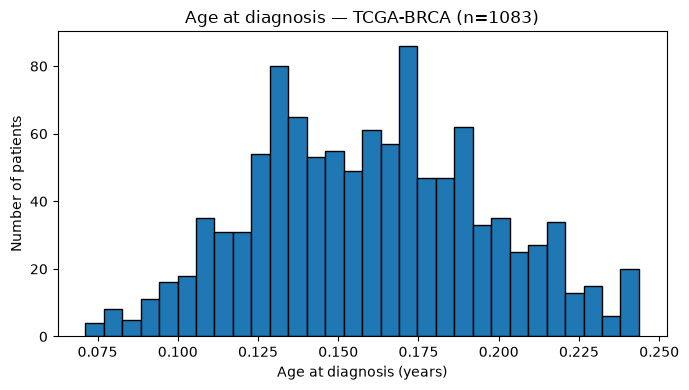

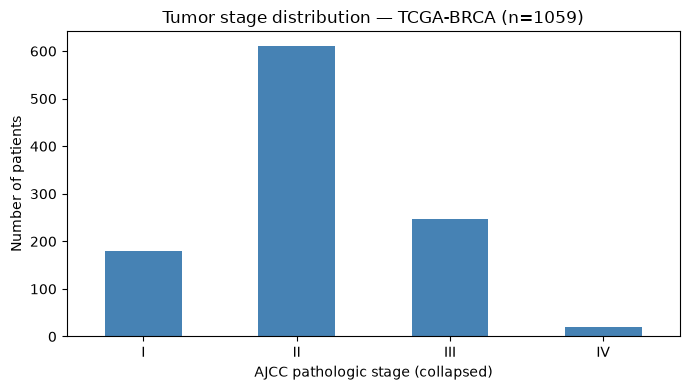

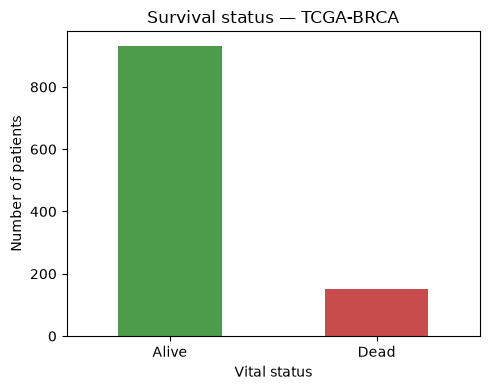

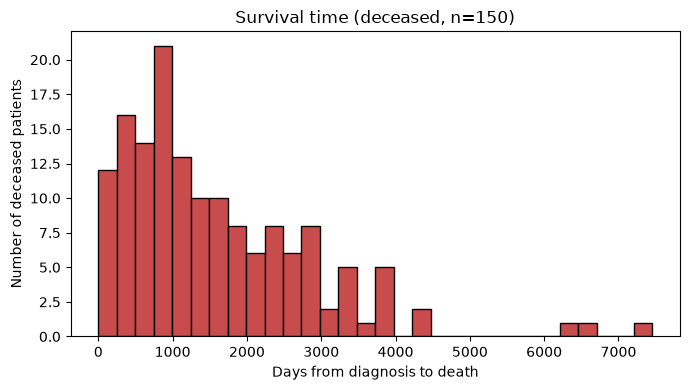


Stage distribution:
stage4
I      180
II     611
III    248
IV      20
Name: count, dtype: int64


In [15]:
# ============================================================
# BLOCK 5 — Clinical descriptive plots (Phase 1, task 7)
# ============================================================
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("../figures", exist_ok=True)

MISSING_TOKENS = ["'--", "--", "Not Reported", "not reported", ""]

def to_num(s):
    return pd.to_numeric(s.replace(MISSING_TOKENS, pd.NA), errors="coerce")

at = pd.read_csv("../data/processed/analysis_table.csv", low_memory=False)
print("Loaded analysis_table:", at.shape)

# --- Plot 1: Age at diagnosis ---
age = to_num(at["demographic.age_at_index"]) / 365.25
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(age.dropna(), bins=30, edgecolor="black")
ax.set_xlabel("Age at diagnosis (years)")
ax.set_ylabel("Number of patients")
ax.set_title(f"Age at diagnosis — TCGA-BRCA (n={age.notna().sum()})")
fig.tight_layout()
fig.savefig("../figures/p1_age_distribution.png", dpi=150)
plt.show()

# --- Plot 2: AJCC stage distribution ---
stage_raw = at["diagnoses.ajcc_pathologic_stage"].replace(MISSING_TOKENS, pd.NA)
# Collapse substages (IA, IIB, ...) to I, II, III, IV
def stage4(s):
    if pd.isna(s): return pd.NA
    m = re.match(r"^\s*Stage\s+(IV|III|II|I)", str(s))
    return m.group(1) if m else pd.NA
at["stage4"] = stage_raw.apply(stage4)

order4 = ["I", "II", "III", "IV"]
counts = at["stage4"].value_counts().reindex(order4)
fig, ax = plt.subplots(figsize=(7, 4))
counts.plot(kind="bar", color="steelblue", ax=ax)
ax.set_xlabel("AJCC pathologic stage (collapsed)")
ax.set_ylabel("Number of patients")
ax.set_title(f"Tumor stage distribution — TCGA-BRCA (n={counts.sum()})")
ax.set_xticklabels(order4, rotation=0)
fig.tight_layout()
fig.savefig("../figures/p1_stage_distribution.png", dpi=150)
plt.show()

# --- Plot 3: Vital status ---
vs = at["demographic.vital_status"].replace(MISSING_TOKENS, pd.NA)
vc = vs.value_counts(dropna=False)
colors = {"Alive": "#4c9c4c", "Dead": "#c94c4c"}
fig, ax = plt.subplots(figsize=(5, 4))
vc.plot(kind="bar", ax=ax,
        color=[colors.get(x, "grey") for x in vc.index])
ax.set_xlabel("Vital status")
ax.set_ylabel("Number of patients")
ax.set_title("Survival status — TCGA-BRCA")
ax.set_xticklabels(vc.index, rotation=0)
fig.tight_layout()
fig.savefig("../figures/p1_vital_status.png", dpi=150)
plt.show()

# --- Plot 4: Survival time (deceased only) ---
d2d = to_num(at["demographic.days_to_death"]).dropna()
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(d2d, bins=30, edgecolor="black", color="#c94c4c")
ax.set_xlabel("Days from diagnosis to death")
ax.set_ylabel("Number of deceased patients")
ax.set_title(f"Survival time (deceased, n={len(d2d)})")
fig.tight_layout()
fig.savefig("../figures/p1_survival_time.png", dpi=150)
plt.show()

print("\nStage distribution:")
print(counts)

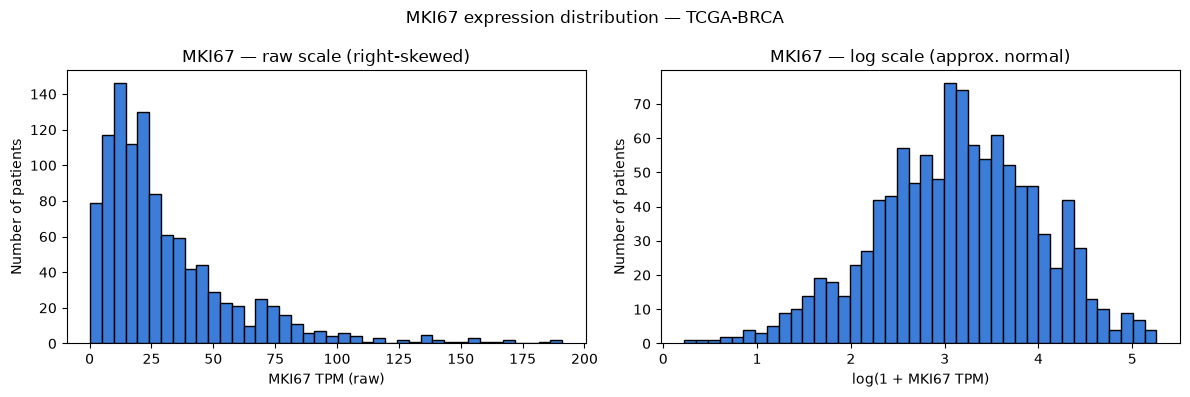

MKI67 raw skewness: 2.1
MKI67 log skewness: -0.22


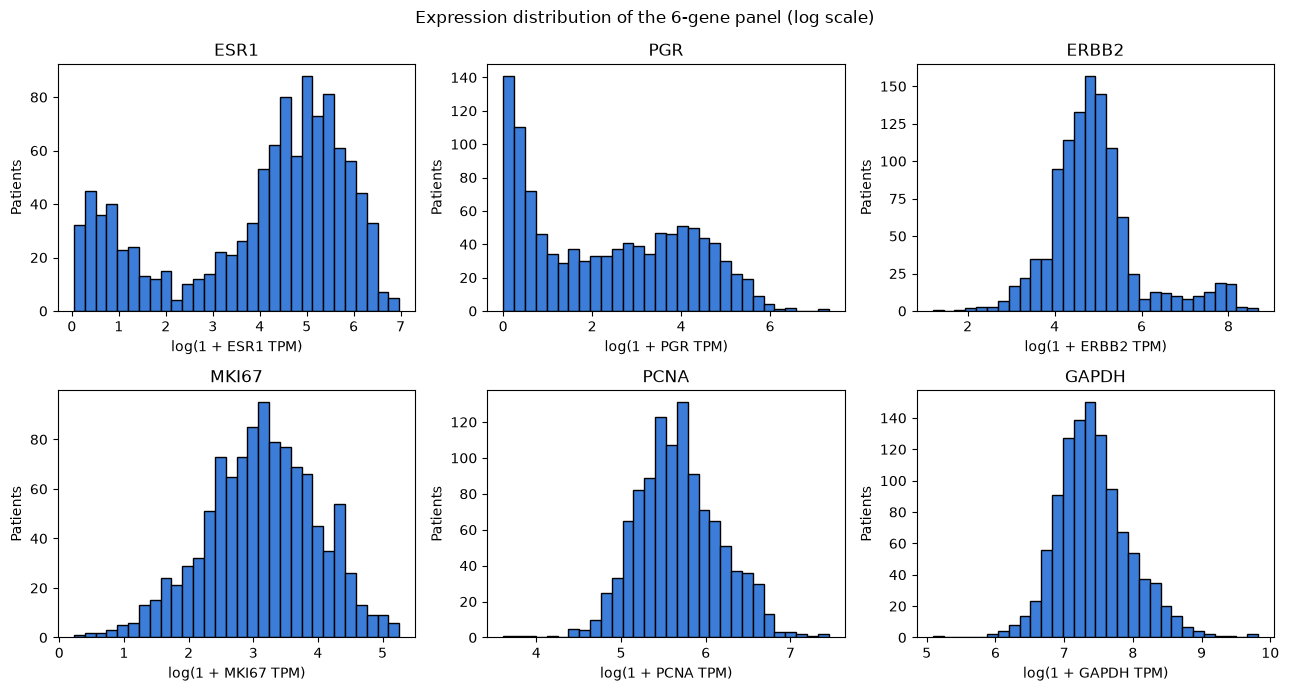

In [16]:
# ============================================================
# BLOCK 5 — Expression descriptive plots (Phase 1, task 7)
# ============================================================
GENE_PANEL = ["ESR1", "PGR", "ERBB2", "MKI67", "PCNA", "GAPDH"]

# --- Plot 5: MKI67 distribution on raw and log scale ---
mki67 = to_num(at["MKI67_tpm"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(mki67.dropna(), bins=40, edgecolor="black", color="#3b7dd8")
axes[0].set_xlabel("MKI67 TPM (raw)")
axes[0].set_ylabel("Number of patients")
axes[0].set_title("MKI67 — raw scale (right-skewed)")

log_mki67 = np.log1p(mki67)
axes[1].hist(log_mki67.dropna(), bins=40, edgecolor="black", color="#3b7dd8")
axes[1].set_xlabel("log(1 + MKI67 TPM)")
axes[1].set_ylabel("Number of patients")
axes[1].set_title("MKI67 — log scale (approx. normal)")
fig.suptitle("MKI67 expression distribution — TCGA-BRCA")
fig.tight_layout()
fig.savefig("../figures/p1_MKI67_distribution.png", dpi=150)
plt.show()

# Quantify skewness to justify the log transform
print("MKI67 raw skewness:", round(mki67.skew(), 2))
print("MKI67 log skewness:", round(log_mki67.skew(), 2))

# --- Plot 6: 6-gene panel overview ---
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for i, g in enumerate(GENE_PANEL):
    ax = axes.flat[i]
    x = np.log1p(to_num(at[f"{g}_tpm"]).dropna())
    ax.hist(x, bins=30, edgecolor="black", color="#3b7dd8")
    ax.set_title(g)
    ax.set_xlabel(f"log(1 + {g} TPM)")
    ax.set_ylabel("Patients")
fig.suptitle("Expression distribution of the 6-gene panel (log scale)")
fig.tight_layout()
fig.savefig("../figures/p1_gene_panel_distributions.png", dpi=150)
plt.show()

=== Descriptive summary: log(MKI67) by stage (4 levels) ===
          n   mean  median     sd     q1     q3
stage4                                         
I       180  2.931   2.921  0.865  2.439  3.542
II      611  3.208   3.205  0.838  2.681  3.799
III     248  3.074   3.135  0.889  2.509  3.690
IV       20  3.134   3.196  0.866  2.645  3.760

=== Descriptive summary: log(MKI67) by stage (Early vs Late) ===
          n   mean  median     sd     q1     q3
stage2                                         
Early   791  3.145   3.159  0.852  2.576  3.747
Late    268  3.078   3.135  0.886  2.522  3.714


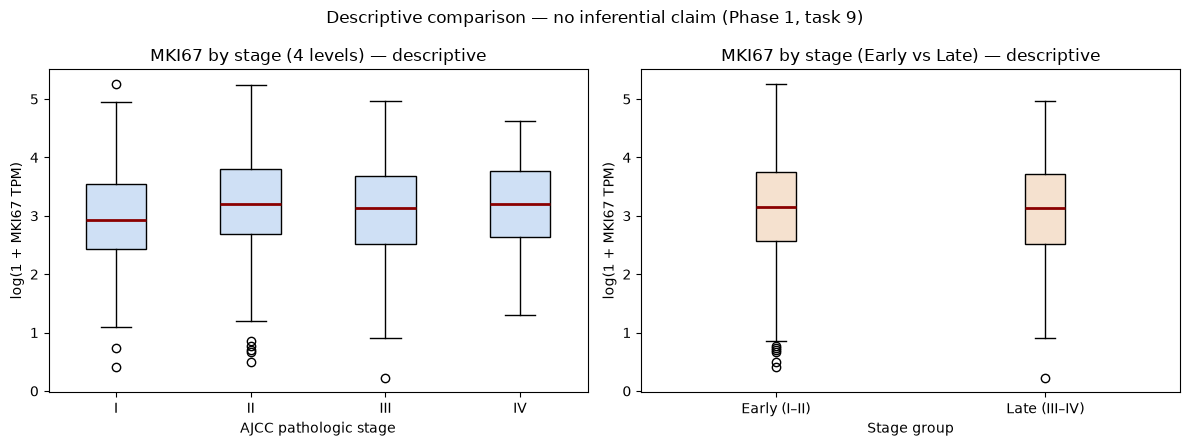


=== 2×2 cross-tab ===
high_MKI67  False  True 
stage                   
Early         395    396
Late          137    131

Re-saved analysis_table.csv with corrected stage4/stage2.


In [17]:
# ============================================================
# BLOCK 5 — Descriptive comparison of MKI67 across stage groups
# (Phase 1, task 9 — descriptive only; NO test, NO p-value)
# ============================================================

# Binary grouping for later phases (defined now, used descriptively here)
at["stage2"] = at["stage4"].map({"I": "Early", "II": "Early",
                                 "III": "Late",  "IV": "Late"})
at["log_MKI67"] = np.log1p(to_num(at["MKI67_tpm"]))

# --- Summary table by 4-level stage ---
summary4 = (at
    .groupby("stage4")["log_MKI67"]
    .agg(n="count", mean="mean", median="median",
         sd="std", q1=lambda s: s.quantile(.25),
         q3=lambda s: s.quantile(.75))
    .reindex(order4)
    .round(3)
)
print("=== Descriptive summary: log(MKI67) by stage (4 levels) ===")
print(summary4)
summary4.to_csv("../figures/p1_summary_MKI67_by_stage4.csv")

summary2 = (at
    .groupby("stage2")["log_MKI67"]
    .agg(n="count", mean="mean", median="median",
         sd="std", q1=lambda s: s.quantile(.25),
         q3=lambda s: s.quantile(.75))
    .reindex(["Early", "Late"])
    .round(3)
)
print("\n=== Descriptive summary: log(MKI67) by stage (Early vs Late) ===")
print(summary2)

data_by_stage = [at.loc[at["stage4"] == s, "log_MKI67"].dropna().values
                 for s in order4]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].boxplot(data_by_stage, tick_labels=order4, patch_artist=True,
                boxprops=dict(facecolor="#cfe0f5"),
                medianprops=dict(color="darkred", linewidth=2))
axes[0].set_xlabel("AJCC pathologic stage")
axes[0].set_ylabel("log(1 + MKI67 TPM)")
axes[0].set_title("MKI67 by stage (4 levels) — descriptive")

data_by_stage2 = [at.loc[at["stage2"] == s, "log_MKI67"].dropna().values
                  for s in ["Early", "Late"]]
axes[1].boxplot(data_by_stage2, tick_labels=["Early (I–II)", "Late (III–IV)"],
                patch_artist=True,
                boxprops=dict(facecolor="#f5e1cf"),
                medianprops=dict(color="darkred", linewidth=2))
axes[1].set_xlabel("Stage group")
axes[1].set_ylabel("log(1 + MKI67 TPM)")
axes[1].set_title("MKI67 by stage (Early vs Late) — descriptive")

fig.suptitle("Descriptive comparison — no inferential claim (Phase 1, task 9)")
fig.tight_layout()
fig.savefig("../figures/p1_MKI67_by_stage_boxplot.png", dpi=150)
plt.show()

median_log = at["log_MKI67"].median()
at["high_MKI67"] = at["log_MKI67"] > median_log
cross = pd.crosstab(at["stage2"], at["high_MKI67"],
                    rownames=["stage"], colnames=["high_MKI67"])
print("\n=== 2×2 cross-tab ===")
print(cross)

at.to_csv("../data/processed/analysis_table.csv", index=False)
print("\nRe-saved analysis_table.csv with corrected stage4/stage2.")